In [1]:
from pathlib import Path

project_path = Path.cwd().parent

print("Current Notebook Folder:")
print(Path.cwd())

print("\nProject Folder:")
print(project_path)

print("\nData Folder Exists:")
print((project_path / "data").exists())

print("\nRaw Folder Exists:")
print((project_path / "data" / "raw").exists())

print("\nFiles inside Raw Folder:")

raw_folder = project_path / "data" / "raw"

if raw_folder.exists():
    for file in raw_folder.iterdir():
        print(file.name)
else:
    print("Raw folder does not exist!")

Current Notebook Folder:
c:\Users\pantv\OneDrive\Desktop\Projects\Retail Intelligence\notebooks

Project Folder:
c:\Users\pantv\OneDrive\Desktop\Projects\Retail Intelligence

Data Folder Exists:
True

Raw Folder Exists:
True

Files inside Raw Folder:
Online Retail.xlsx.xlsx


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
excel_path = project_path / "data" / "raw" / "Online Retail.xlsx.xlsx"
df = pd.read_excel(excel_path)
print("Dataset Shape:", df.shape)
print("Total Records:", len(df))
display(df.head())

Dataset Shape: (541909, 8)
Total Records: 541909


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df_clean = df.copy()
print("Original Rows:", len(df_clean))

Original Rows: 541909


In [5]:
df_clean = df_clean.drop_duplicates()

In [6]:
df_clean["InvoiceDate"] = pd.to_datetime(
df_clean["InvoiceDate"], errors="coerce")

df_clean["Quantity"] = pd.to_numeric(
df_clean["Quantity"], errors="coerce")

df_clean["UnitPrice"] = pd.to_numeric(
df_clean["UnitPrice"], errors="coerce")

df_clean["CustomerID"] = pd.to_numeric(
df_clean["CustomerID"], errors="coerce")

In [7]:
df_clean = df_clean[
df_clean["InvoiceNo"].astype(str).str.startswith("C")].copy()

In [8]:
df_clean = df_clean[
(df_clean["Quantity"] > 0) &
(df_clean["UnitPrice"] > 0)].copy()


In [9]:
df_clean = df_clean.dropna(
subset=["InvoiceDate", "CustomerID", "InvoiceNo"]).copy()

In [10]:
df_clean["CustomerID"] = (
df_clean["CustomerID"].astype("int64").astype(str))

In [11]:
df_clean["Revenue"] = (
df_clean["Quantity"] * df_clean["UnitPrice"])

In [12]:
print("Cleaned Dataset Shape:", df_clean.shape)
print("Unique Customers:", df_clean["CustomerID"].nunique())
print("Missing Customer IDs:", df_clean["CustomerID"].isnull().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Total Revenue:", round(df_clean["Revenue"].sum(), 2))
display(df_clean.head())

Cleaned Dataset Shape: (0, 9)
Unique Customers: 0
Missing Customer IDs: 0
Duplicate Rows: 0
Total Revenue: 0.0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue


In [13]:
test_df = df.copy()
print("1. Original Rows:", len(test_df))

1. Original Rows: 541909


In [14]:
print("\nColumn Names:")
print(test_df.columns.tolist())

print("\nData Types:")
print(test_df.dtypes)


Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


In [15]:
print("\nMissing Values:")
print(test_df.isnull().sum())


Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [16]:
print("\nFILTER TESTING")

print("After removing duplicates:",
len(test_df.drop_duplicates()))

print("Positive Quantity:",
(test_df["Quantity"] > 0).sum())

print("Positive UnitPrice:",
(test_df["UnitPrice"] > 0).sum())

print("Non-cancelled invoices:",
(test_df["InvoiceNo"].astype(str).str.startswith("C")).sum())

print("Valid CustomerID:",
test_df["CustomerID"].notna().sum())

print("Valid InvoiceDate:",
pd.to_datetime(test_df["InvoiceDate"], errors="coerce").notna().sum())


FILTER TESTING
After removing duplicates: 536641
Positive Quantity: 531285
Positive UnitPrice: 539392
Non-cancelled invoices: 9288
Valid CustomerID: 406829
Valid InvoiceDate: 541909


In [17]:
print("Invoice Number Samples:")
print(df["InvoiceNo"].head(15).tolist())

cancelled_mask = df["InvoiceNo"].astype(str).str.startswith("C")

print("\nCancelled Invoice Rows:", cancelled_mask.sum())

print("Non-Cancelled Invoice Rows:", (~cancelled_mask).sum())

print("\nInvoice Number Data Type:")
print(df["InvoiceNo"].dtype)

Invoice Number Samples:
[536365, 536365, 536365, 536365, 536365, 536365, 536365, 536366, 536366, 536367, 536367, 536367, 536367, 536367, 536367]

Cancelled Invoice Rows: 9288
Non-Cancelled Invoice Rows: 532621

Invoice Number Data Type:
object


In [18]:
test_df = df.drop_duplicates().copy()
mask = (
    (~test_df["InvoiceNo"].astype(str).str.startswith("C")) &
    (test_df["Quantity"] > 0) &
    (test_df["UnitPrice"] > 0) &
    (test_df["CustomerID"].notna()) &
    (pd.to_datetime(test_df["InvoiceDate"], errors="coerce").notna()))

print("Rows after all filters:", mask.sum())
print("Expected to be greater than zero.")

Rows after all filters: 392692
Expected to be greater than zero.


In [19]:
df_clean = df.copy()

In [20]:
df_clean = df_clean.drop_duplicates().copy()

In [21]:
df_clean = df_clean[
~df_clean["InvoiceNo"].astype(str).str.startswith("C")].copy()

In [22]:
df_clean = df_clean[
(df_clean["Quantity"] > 0) &
(df_clean["UnitPrice"] > 0)].copy()

In [23]:
df_clean = df_clean.dropna(
    subset=["CustomerID", "InvoiceDate", "InvoiceNo"]
).copy()

In [24]:
df_clean["CustomerID"] = (
    df_clean["CustomerID"].astype("int64").astype(str)
)

In [25]:
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

In [26]:
print("Original Rows:", len(df))
print("Cleaned Rows:", len(df_clean))
print("Unique Customers:", df_clean["CustomerID"].nunique())
print("Missing Customer IDs:", df_clean["CustomerID"].isnull().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Total Revenue:", round(df_clean["Revenue"].sum(), 2))

Original Rows: 541909
Cleaned Rows: 392692
Unique Customers: 4338
Missing Customer IDs: 0
Duplicate Rows: 0
Total Revenue: 8887208.89


In [27]:
output_folder = project_path / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(
output_folder / "retail_cleaned.csv",
index=False)


In [28]:
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df_clean.groupby("CustomerID").agg(
Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
Frequency=("InvoiceNo", "nunique"),
Monetary=("Revenue", "sum")).reset_index()
print("RFM Calculation Completed!")
print("RFM Dataset Shape:", rfm.shape)
display(rfm.head(10))


RFM Calculation Completed!
RFM Dataset Shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43


In [29]:
print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nData Types:")
print(rfm.dtypes)

print("\nRFM Statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))


Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Data Types:
CustomerID        str
Recency         int64
Frequency       int64
Monetary      float64
dtype: object

RFM Statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


In [30]:
rfm["Recency"] = pd.to_numeric(rfm["Recency"], errors="coerce")
rfm["Frequency"] = pd.to_numeric(rfm["Frequency"], errors="coerce")
rfm["Monetary"] = pd.to_numeric(rfm["Monetary"], errors="coerce")

rfm = rfm.dropna(
subset=["Recency", "Frequency", "Monetary"]).copy()

if len(rfm) < 5:
    raise ValueError("RFM scoring requires at least 5 customers.")

In [31]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

In [32]:
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [33]:
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [34]:
display(rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346,326,1,77183.60,1,1,5
1,12347,2,7,4310.00,5,5,5
2,12348,75,4,1797.24,2,4,4
3,12349,19,1,1757.55,4,1,4
4,12350,310,1,334.40,1,1,2
5,12352,36,8,2506.04,3,5,5
6,12353,204,1,89.00,1,1,1
7,12354,232,1,1079.40,1,1,4
8,12355,214,1,459.40,1,1,2
9,12356,23,3,2811.43,4,3,5


In [35]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(
    rfm[
        ["CustomerID", "Recency", "Frequency",
         "Monetary", "R_Score", "F_Score",
         "M_Score", "RFM_Score"]
].head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,2,7,4310.00,5,5,5,555
2,12348,75,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,310,1,334.40,1,1,2,112
5,12352,36,8,2506.04,3,5,5,355
6,12353,204,1,89.00,1,1,1,111
7,12354,232,1,1079.40,1,1,4,114
8,12355,214,1,459.40,1,1,2,112
9,12356,23,3,2811.43,4,3,5,435


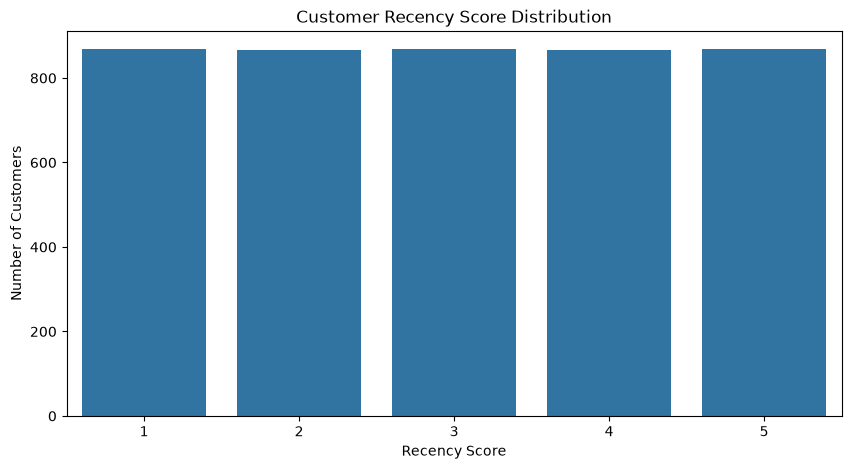

In [36]:
plt.figure(figsize=(10, 5))

sns.countplot(data=rfm, x="R_Score")

plt.title("Customer Recency Score Distribution")
plt.xlabel("Recency Score")
plt.ylabel("Number of Customers")

plt.show()

In [37]:
def segment_customer(row):

    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Loyal Customers"

    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "New / Potential Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost / Hibernating"

    else:
        return "Regular Customers"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

display(rfm.head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,Lost / Hibernating
1,12347,2,7,4310.00,5,5,5,555,Champions
2,12348,75,4,1797.24,2,4,4,244,At Risk Customers
3,12349,19,1,1757.55,4,1,4,414,New / Potential Customers
4,12350,310,1,334.40,1,1,2,112,Lost / Hibernating
5,12352,36,8,2506.04,3,5,5,355,Loyal Customers
6,12353,204,1,89.00,1,1,1,111,Lost / Hibernating
7,12354,232,1,1079.40,1,1,4,114,Lost / Hibernating
8,12355,214,1,459.40,1,1,2,112,Lost / Hibernating
9,12356,23,3,2811.43,4,3,5,435,Regular Customers


In [38]:
segment_counts = rfm["Segment"].value_counts()
display(segment_counts)

Segment
Lost / Hibernating           1074
Champions                     942
Regular Customers             843
At Risk Customers             661
Loyal Customers               508
New / Potential Customers     310
Name: count, dtype: int64

In [39]:
segment_analysis = rfm.groupby("Segment").agg(
Customers=("CustomerID", "count"),
Avg_Recency=("Recency", "mean"),
Avg_Frequency=("Frequency", "mean"),
Avg_Monetary=("Monetary", "mean"),
Total_Revenue=("Monetary", "sum")
).round(2)

display(segment_analysis)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Segment,,,,,
At Risk Customers,661,150.64,3.41,1246.46,823912.44
Champions,942,12.50,11.20,6091.24,5737952.12
Lost / Hibernating,1074,216.68,1.10,487.71,523803.28
Loyal Customers,508,37.21,5.12,1826.03,927623.75
New / Potential Customers,310,18.10,1.25,458.84,142239.44
Regular Customers,843,38.97,1.85,867.95,731677.86


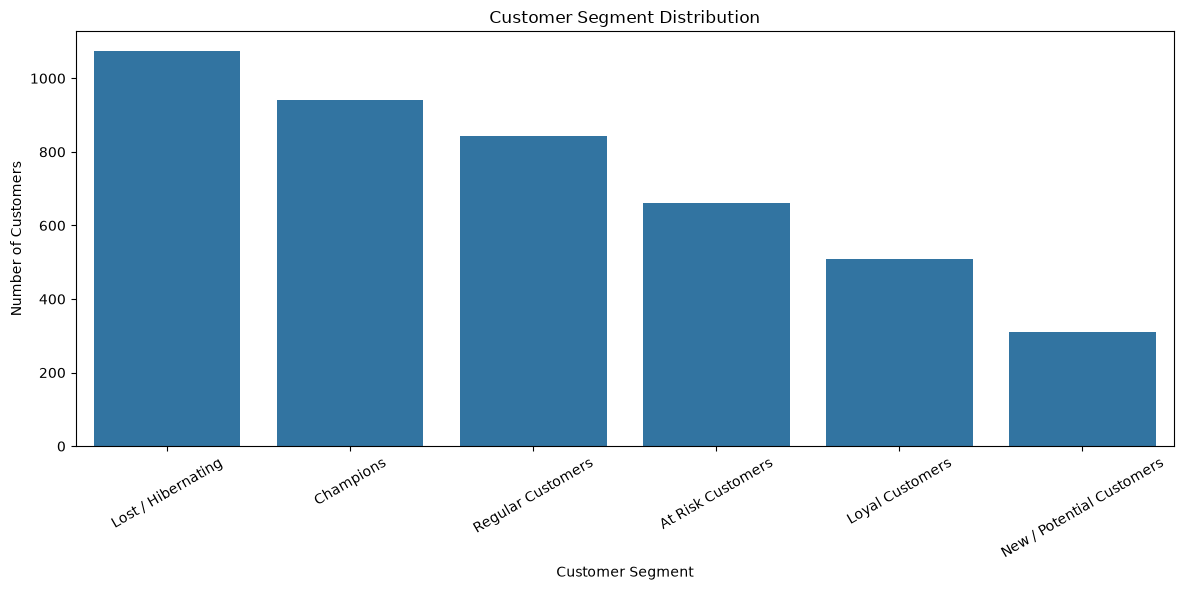

In [40]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=rfm,
    x="Segment",
    order=rfm["Segment"].value_counts().index)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [42]:
rfm_model = rfm[["Recency", "Frequency", "Monetary"]].copy()

In [43]:
rfm_model["Frequency"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary"] = np.log1p(rfm_model["Monetary"])

In [44]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_model)
print("Scaled Data Shape:", rfm_scaled.shape)

Scaled Data Shape: (4338, 3)


In [45]:
print("\nFirst 5 Scsled Rows:")
print(rfm_scaled[:5])


First 5 Scsled Rows:
[[ 2.33457414 -0.95521426  3.7077163 ]
 [-0.90534032  1.07442519  1.41490344]
 [-0.17535959  0.38630445  0.72002428]
 [-0.73534481 -0.95521426  0.70228691]
 [ 2.17457836 -0.95521426 -0.61451388]]


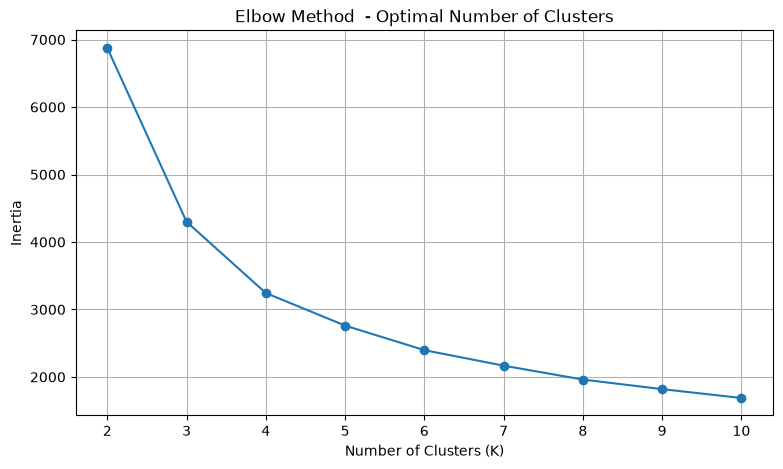

In [46]:
inertia = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(rfm_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertia, marker="o")
plt.title("Elbow Method  - Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [47]:
optimal_k = 4 
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
print("\nTotal Clusters:", rfm["Cluster"].nunique())
print("\nCluster Distribution:")
print(rfm["Cluster"].value_counts().sort_index())
display(rfm.head(10))


Total Clusters: 4

Cluster Distribution:
Cluster
0    1377
1     938
2     571
3    1452
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster
0,12346,326,1,77183.60,1,1,5,115,Lost / Hibernating,3
1,12347,2,7,4310.00,5,5,5,555,Champions,2
2,12348,75,4,1797.24,2,4,4,244,At Risk Customers,3
3,12349,19,1,1757.55,4,1,4,414,New / Potential Customers,3
4,12350,310,1,334.40,1,1,2,112,Lost / Hibernating,1
5,12352,36,8,2506.04,3,5,5,355,Loyal Customers,2
6,12353,204,1,89.00,1,1,1,111,Lost / Hibernating,1
7,12354,232,1,1079.40,1,1,4,114,Lost / Hibernating,1
8,12355,214,1,459.40,1,1,2,112,Lost / Hibernating,1
9,12356,23,3,2811.43,4,3,5,435,Regular Customers,3


In [48]:
cluster_analysis = rfm.groupby("Cluster").agg(
    Cuatomers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
),round(2)
print("CUTOMER CLUSTER ANALYSIS")
display(cluster_analysis)

CUTOMER CLUSTER ANALYSIS


(         Cuatomers  Avg_Recency  Avg_Frequency  Avg_Monetary  Total_Revenue
 Cluster                                                                    
 0             1377    58.042847       1.514887    384.216050     529065.501
 1              938   259.406183       1.371002    385.388550     361494.460
 2              571    19.770578      15.842382   9823.434028    5609180.830
 3             1452    46.064738       4.210744   1644.261779    2387468.103,
 2)

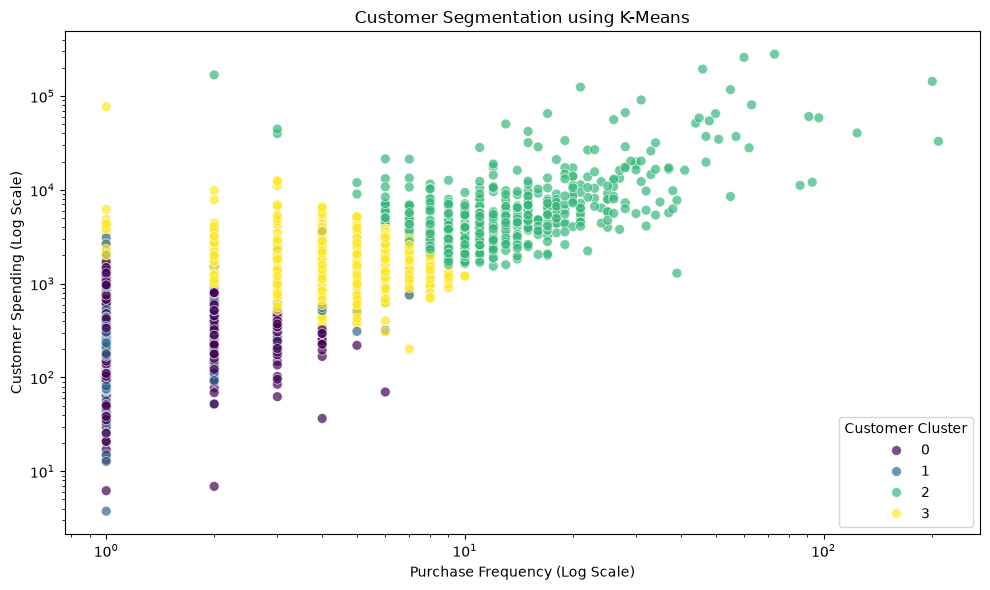

In [49]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.7,
    s=50
)
plt.xscale("log")
plt.yscale("log")
plt.title("Customer Segmentation using K-Means")
plt.xlabel("Purchase Frequency (Log Scale)")
plt.ylabel("Customer Spending (Log Scale)")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.show()


In [50]:
score = silhouette_score(
    rfm_scaled,
    rfm["Cluster"]
)
print("K-MEANS MODEL EVALUATION")
print("Number of Clusters:", rfm["Cluster"].nunique())
print("Silhouette Score:", round(score, 3))

K-MEANS MODEL EVALUATION
Number of Clusters: 4
Silhouette Score: 0.38


In [51]:
print("FINAL CLUSTER PROFILE")

final_cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(
    final_cluster_profile.sort_values(
        by="Avg_Monetary",
        ascending=False
    )
)

FINAL CLUSTER PROFILE


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Cluster,,,,,
2,571,19.77,15.84,9823.43,5609180.83
3,1452,46.06,4.21,1644.26,2387468.10
1,938,259.41,1.37,385.39,361494.46
0,1377,58.04,1.51,384.22,529065.50


In [52]:
cluster_names = {
    0: "Occasional / Low Value",
    1: "Dormant Customers",
    2: "Champions",
    3: "Loyal / Regular Customers"
}
rfm["Cluster_Name"] = rfm["Cluster"].map(cluster_names)

display(
    rfm[
        ["CustomerID", "Recency", "Frequency",
         "Monetary", "Cluster", "Cluster_Name"]
    ].head(15)
)

,CustomerID,Recency,Frequency,Monetary,Cluster,Cluster_Name
0,12346,326,1,77183.60,3,Loyal / Regular Customers
1,12347,2,7,4310.00,2,Champions
2,12348,75,4,1797.24,3,Loyal / Regular Customers
3,12349,19,1,1757.55,3,Loyal / Regular Customers
4,12350,310,1,334.40,1,Dormant Customers
5,12352,36,8,2506.04,2,Champions
6,12353,204,1,89.00,1,Dormant Customers
7,12354,232,1,1079.40,1,Dormant Customers
8,12355,214,1,459.40,1,Dormant Customers
9,12356,23,3,2811.43,3,Loyal / Regular Customers


In [53]:
output_file = output_folder / "rfm_customer_segments.csv"

rfm.to_csv(
    output_file,
    index=False
)

print("File Location:", output_file)
print("Total Customers:", len(rfm))
print("Total Clusters:", rfm["Cluster"].nunique())
print("\nFinal Dataset Preview:")
display(rfm.head(10))

File Location: c:\Users\pantv\OneDrive\Desktop\Projects\Retail Intelligence\data\processed\rfm_customer_segments.csv
Total Customers: 4338
Total Clusters: 4

Final Dataset Preview:


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster,Cluster_Name
0,12346,326,1,77183.60,1,1,5,115,Lost / Hibernating,3,Loyal / Regular Customers
1,12347,2,7,4310.00,5,5,5,555,Champions,2,Champions
2,12348,75,4,1797.24,2,4,4,244,At Risk Customers,3,Loyal / Regular Customers
3,12349,19,1,1757.55,4,1,4,414,New / Potential Customers,3,Loyal / Regular Customers
4,12350,310,1,334.40,1,1,2,112,Lost / Hibernating,1,Dormant Customers
5,12352,36,8,2506.04,3,5,5,355,Loyal Customers,2,Champions
6,12353,204,1,89.00,1,1,1,111,Lost / Hibernating,1,Dormant Customers
7,12354,232,1,1079.40,1,1,4,114,Lost / Hibernating,1,Dormant Customers
8,12355,214,1,459.40,1,1,2,112,Lost / Hibernating,1,Dormant Customers
9,12356,23,3,2811.43,4,3,5,435,Regular Customers,3,Loyal / Regular Customers
